In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

sns.set_theme(style="whitegrid")

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print("Dataset shape:", df.shape)
df[["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].head()

Dataset shape: (891, 12)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [2]:
data = df[["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].copy()

# Fill missing values
data["Age"] = data["Age"].fillna(data["Age"].median())
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])

# Feature engineering & encoding
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
data["Sex_num"] = data["Sex"].map({"male": 0, "female": 1})
data = pd.get_dummies(data, columns=["Embarked"], drop_first=True)

features = ["Pclass", "Sex_num", "Age", "SibSp", "Parch", "FamilySize", "Fare"] + [
    col for col in data.columns if col.startswith("Embarked_")
]
X = data[features]
y = data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 712
Testing samples: 179


In [3]:
clf = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

train_acc = accuracy_score(y_train, clf.predict(X_train))
test_acc = accuracy_score(y_test, y_pred)

print(f"Train Accuracy: {train_acc:.4f} ({train_acc * 100:.2f}%)")
print(f"Test Accuracy:  {test_acc:.4f} ({test_acc * 100:.2f}%)\n")
print("Classification Report:\n", classification_report(y_test, y_pred))

Train Accuracy: 0.8329 (83.29%)
Test Accuracy:  0.7765 (77.65%)

Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.92      0.83       110
           1       0.81      0.55      0.66        69

    accuracy                           0.78       179
   macro avg       0.79      0.73      0.74       179
weighted avg       0.78      0.78      0.77       179



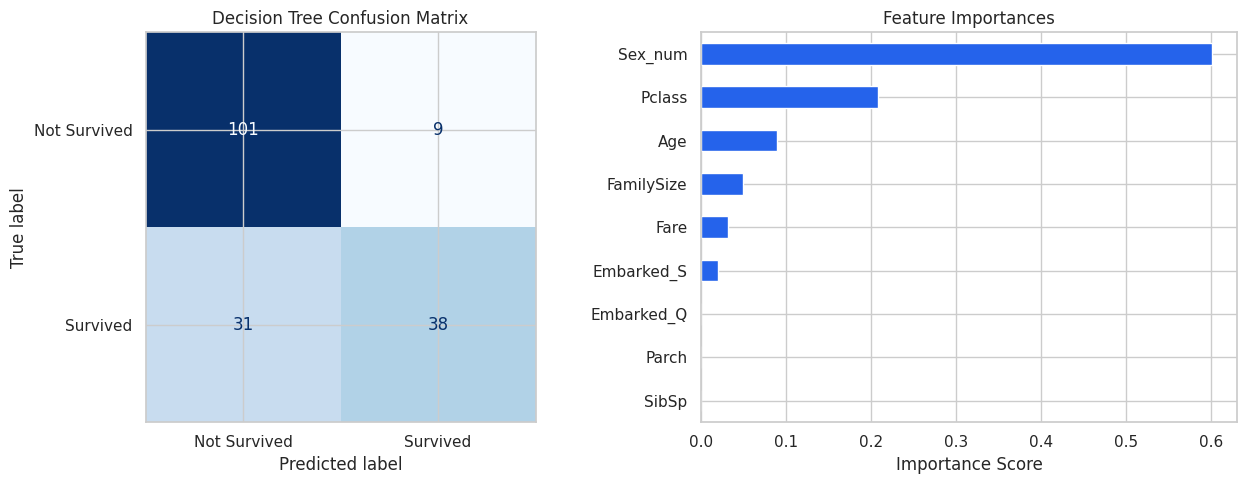

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Survived", "Survived"])
disp.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Decision Tree Confusion Matrix")

importances = pd.Series(clf.feature_importances_, index=features).sort_values(ascending=True)
importances.plot(kind="barh", color="#2563EB", ax=axes[1])
axes[1].set_title("Feature Importances")
axes[1].set_xlabel("Importance Score")

plt.tight_layout()
plt.show()

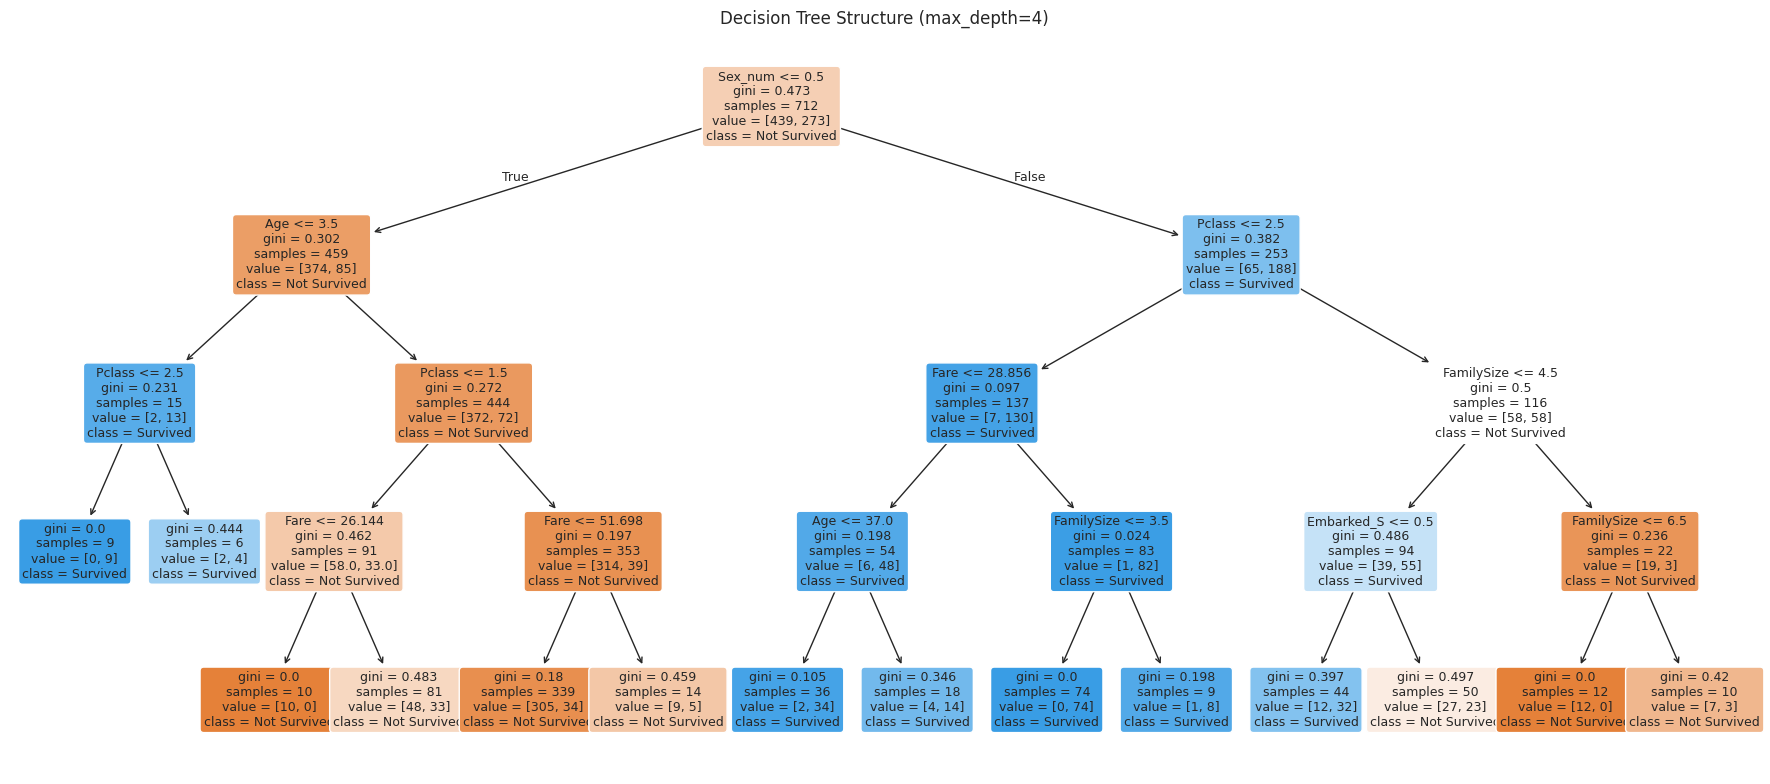

In [5]:
plt.figure(figsize=(18, 8))
plot_tree(
    clf,
    feature_names=features,
    class_names=["Not Survived", "Survived"],
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title("Decision Tree Structure (max_depth=4)")
plt.tight_layout()
plt.show()